In [24]:
from pathlib import Path
import tempfile
import warnings
import textwrap

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Works when the kernel starts in either the repo root or notebooks/.
notebook_dir = next(
    (p / 'notebooks' if (p / 'notebooks' / 'markets.ipynb').exists() else p)
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'notebooks' / 'markets.ipynb').exists() or (p / 'markets.ipynb').exists()
)
# Change this one line to analyze a different downloaded export.
CSV_PATH = notebook_dir / 'data/supabase_exports/20261028T050019Z_hxekxttx/markets.csv'
if not CSV_PATH.is_file():
    raise FileNotFoundError(f'CSV not found: {CSV_PATH}')
FIGURE_DIR = notebook_dir / 'markets_eda' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
BLUE, ORANGE, GREEN = '#2864A5', '#D87A24', '#238A73'

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## Load the data and make the date filter explicit

We read only market names/identifiers, dates, prices, and reported trading volume into the analysis table. `\N` means missing. Reported zero trading and missing trading data remain separate.

In [25]:
if 'con' in globals():
    con.close()
if '_db_temp' in globals():
    _db_temp.cleanup()
_db_temp = tempfile.TemporaryDirectory(prefix='markets_eda_')
con = duckdb.connect(str(Path(_db_temp.name) / 'eda.duckdb'),
                     config={'memory_limit': '512MB', 'threads': 2})
con.execute("SET TimeZone = 'UTC'")

def query(sql):
    with warnings.catch_warnings():
        # Suppress only a known deprecation in DuckDB's pandas adapter.
        warnings.filterwarnings('ignore', message='The inplace keyword in DataFrame.drop is deprecated.*')
        return con.execute(sql).fetchdf()

csv_literal = str(CSV_PATH).replace("'", "''")
con.execute(f"""
    CREATE TABLE raw AS
    SELECT * FROM read_csv('{csv_literal}', header=true, all_varchar=true,
                          nullstr='\\N', sample_size=20480)
""")
numeric_cols = ['last_trade_price', 'volume_24hr', 'volume_1wk']
expressions = ['slug', 'title', 'condition_id', 'event_slug', 'resolution_source']
expressions += [f'CASE WHEN isfinite(try_cast({c} AS DOUBLE)) '
                f'THEN try_cast({c} AS DOUBLE) END AS {c}' for c in numeric_cols]
expressions += ['try_cast(created_at AS TIMESTAMPTZ) AS created_at',
                'try_cast(end_date AS TIMESTAMPTZ) AS end_date',
                'to_timestamp(try_cast(synced_at AS BIGINT)) AS synced_at']
con.execute('CREATE TABLE markets AS SELECT ' + ', '.join(expressions) + ' FROM raw')
con.execute('DROP TABLE raw')
con.execute("""
    CREATE VIEW study_markets AS
    SELECT *,
           date_diff('second', created_at, synced_at) / 86400.0 AS market_age_days,
           date_diff('second', synced_at, end_date) / 86400.0 AS days_to_end
    FROM markets WHERE created_at <= synced_at AND synced_at < end_date
""")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

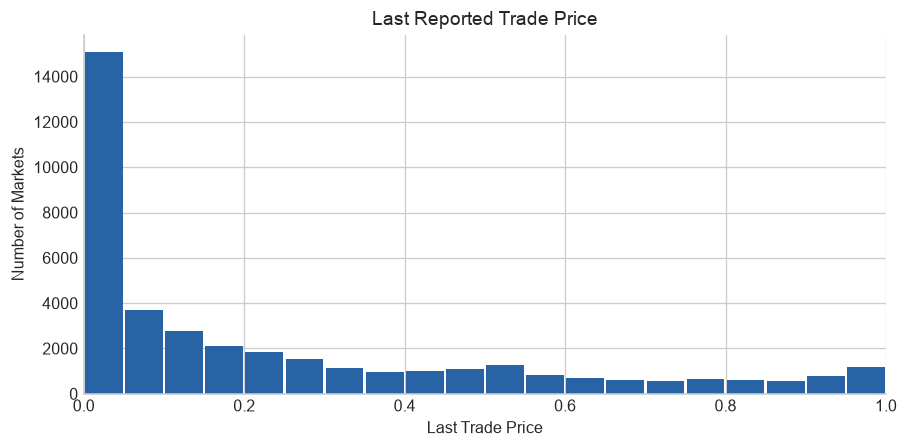

In [26]:
price_hist = query("""
    SELECT least(19, floor(last_trade_price * 20)) AS bin, count(*) AS markets
    FROM study_markets WHERE last_trade_price BETWEEN 0 AND 1
    GROUP BY 1 ORDER BY 1
""")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar((price_hist['bin'] + 0.5) / 20, price_hist['markets'], width=0.047, color=BLUE)
ax.set(title=f"Last Reported Trade Price",
       xlabel='Last Trade Price', ylabel='Number of Markets', xlim=(0, 1))
finish(fig, 'retained_01_prices')

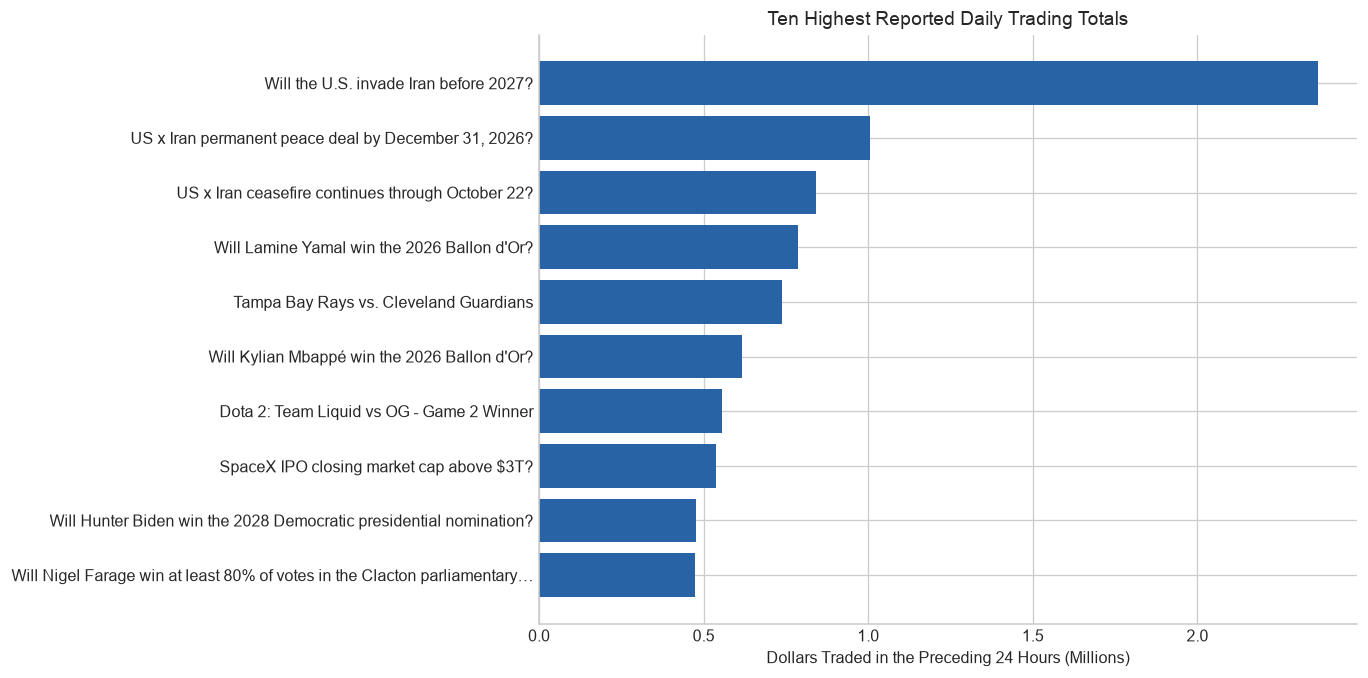

In [28]:
top_daily = query("""
    SELECT title, volume_24hr AS daily_volume_dollars
    FROM study_markets WHERE volume_24hr > 0
    ORDER BY volume_24hr DESC, slug LIMIT 10
""")
fig, ax = plt.subplots(figsize=(12, 6))
top_plot = top_daily.iloc[::-1]
positions = np.arange(len(top_plot))
labels = [textwrap.shorten(str(t), width=75, placeholder='…') for t in top_plot['title']]
ax.barh(positions, top_plot['daily_volume_dollars'] / 1e6, color=BLUE)
ax.set_yticks(positions, labels=labels)
ax.set(title='Ten Highest Reported Daily Trading Totals',
       xlabel='Dollars Traded in the Preceding 24 Hours (Millions)', ylabel='')
finish(fig, 'new_01_top_daily_trading')

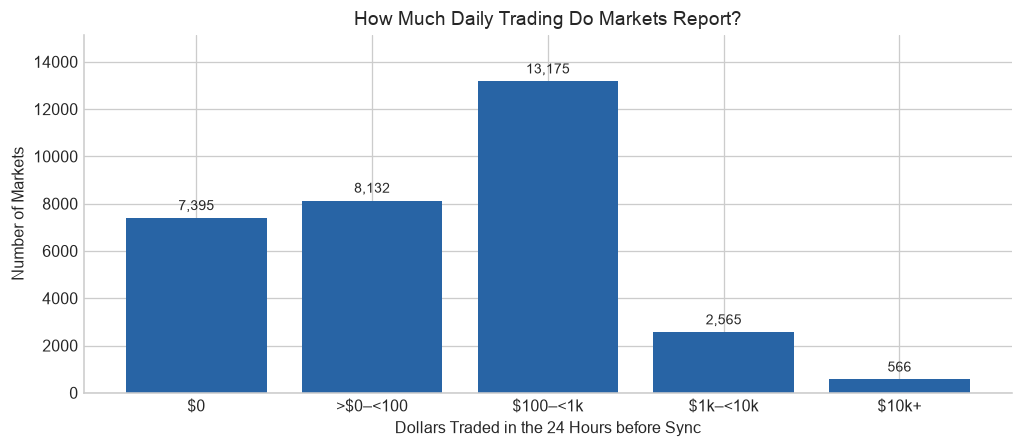

In [29]:
daily_band_names = {0: '$0', 1: '>$0–<100', 2: '$100–<1k',
                    3: '$1k–<10k', 4: '$10k+'}
daily_bands = query("""
    SELECT CASE WHEN volume_24hr = 0 THEN 0 WHEN volume_24hr < 100 THEN 1
                WHEN volume_24hr < 1000 THEN 2 WHEN volume_24hr < 10000 THEN 3
                ELSE 4 END AS band, count(*) AS markets
    FROM study_markets WHERE volume_24hr >= 0 GROUP BY 1 ORDER BY 1
""").set_index('band').reindex(range(5), fill_value=0).reset_index()
daily_bands['daily_trading_range'] = daily_bands['band'].map(daily_band_names)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(daily_bands['daily_trading_range'], daily_bands['markets'], color=BLUE)
ax.bar_label(bars, labels=[f'{v:,}' for v in daily_bands['markets']], padding=3, fontsize=9)
ax.set(title='How Much Daily Trading Do Markets Report?',
       xlabel='Dollars Traded in the 24 Hours before Sync', ylabel='Number of Markets')
ax.margins(y=0.15)
finish(fig, 'new_02_daily_trading_ranges')

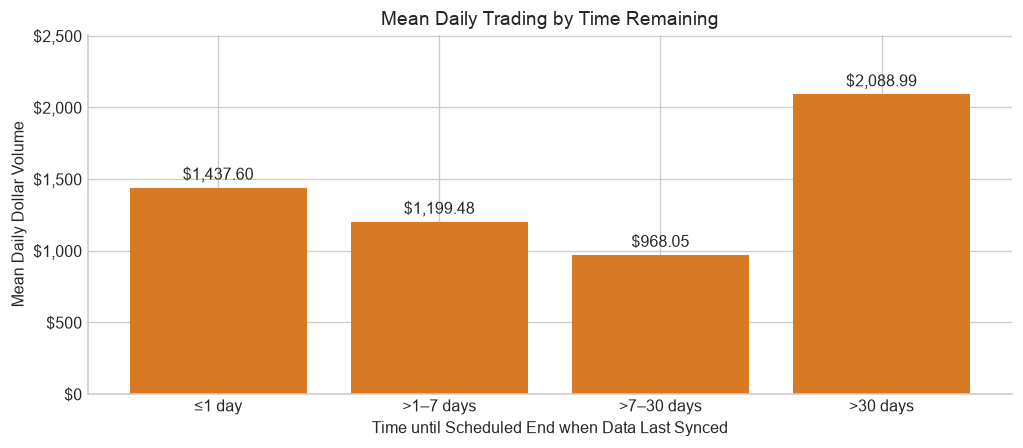

In [31]:
deadline_names = {1: '≤1 day', 2: '>1–7 days', 3: '>7–30 days', 4: '>30 days'}
deadline_summary = query("""
    WITH grouped AS (
        SELECT *, CASE WHEN days_to_end <= 1 THEN 1 WHEN days_to_end <= 7 THEN 2
                       WHEN days_to_end <= 30 THEN 3 ELSE 4 END AS band
        FROM study_markets
    )
    SELECT band,
           avg(volume_24hr) FILTER (WHERE volume_24hr >= 0) AS mean_dollars
    FROM grouped GROUP BY 1 ORDER BY 1
""").set_index('band').reindex([1, 2, 3, 4]).reset_index()
deadline_summary['time_remaining'] = deadline_summary['band'].map(deadline_names)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(deadline_summary['time_remaining'], deadline_summary['mean_dollars'], color=ORANGE)
ax.bar_label(bars, labels=[f'${v:,.2f}' if pd.notna(v) else 'No data'
                          for v in deadline_summary['mean_dollars']], padding=3)
ax.set(title='Mean Daily Trading by Time Remaining',
       xlabel='Time until Scheduled End when Data Last Synced', ylabel='Mean Daily Dollar Volume')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.margins(y=0.2)
finish(fig, 'new_04_daily_trading_by_deadline')

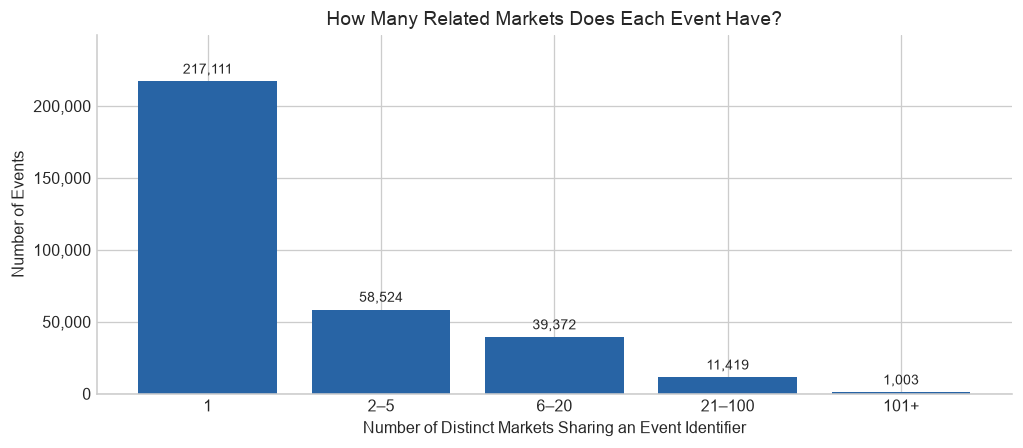

In [32]:
event_names = {1: '1', 2: '2–5', 3: '6–20', 4: '21–100', 5: '101+'}
con.execute("""
    CREATE OR REPLACE VIEW event_sizes AS
    SELECT event_slug, count(DISTINCT slug) AS number_of_markets
    FROM markets WHERE event_slug IS NOT NULL AND slug IS NOT NULL GROUP BY event_slug
""")
event_groups = query("""
    SELECT CASE WHEN number_of_markets = 1 THEN 1 WHEN number_of_markets <= 5 THEN 2
                WHEN number_of_markets <= 20 THEN 3 WHEN number_of_markets <= 100 THEN 4
                ELSE 5 END AS band, count(*) AS events
    FROM event_sizes GROUP BY 1 ORDER BY 1
""").set_index('band').reindex(range(1, 6), fill_value=0).reset_index()
event_groups['markets_per_event'] = event_groups['band'].map(event_names)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(event_groups['markets_per_event'], event_groups['events'], color=BLUE)
ax.bar_label(bars, labels=[f'{v:,}' for v in event_groups['events']], padding=3, fontsize=9)
ax.set(title='How Many Related Markets Does Each Event Have?',
       xlabel='Number of Distinct Markets Sharing an Event Identifier', ylabel='Number of Events')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.margins(y=0.15)
finish(fig, 'new_05_related_markets_per_event')

In [33]:
MIN_POSITIVE_MARKETS = 20
MIN_POSITIVE_EVENTS = 3

# Approximate topic labels, not official categories. First matching rule wins.
# Keep unmatched markets in Other instead of excluding them.
TOPIC_RULES = [
    ('Weather & natural events',
     r'temperature|fahrenheit|celsius|rainfall|snowfall|hurricane|earthquake|tornado|precipitation|weather[.]gov|aviationweather[.]gov|highest.temp|lowest.temp|will.it.rain'),
    ('Crypto',
     r'bitcoin|ethereum|dogecoin|solana|cryptocurrency|crypto|binance[.]com|coinbase[.]com|(^|[^a-z0-9])(btc|eth|xrp|usdt)([^a-z0-9]|$)'),
    ('Sports & esports',
     r'o/u|team.total|series.spread|first.round.leader|pgatour[.]com|lpga[.]com|afa[.]com[.]ar|cbf[.]com[.]br|proleague[.]be|ligaportugal[.]pt|fortunaliga[.]cz|efa[.]com[.]eg|tennis|soccer|football|basketball|baseball|hockey|cricket|golf|boxing|formula.1|motogp|dota|counter.strike|league.of.legends|esports|valorant|world.cup|ballon.d.or|set.handicap|total.goals|both.teams.to.score|atptour[.]com|itftennis[.]com|wtatennis[.]com|uefa[.]com|nba[.]com|nfl[.]com|mlb[.]com|espn[.]com|fifa[.]com|flashscore[.]|sofascore[.]|hltv[.]org|gol[.]gg|(^|[^a-z0-9])(nba|wnba|nfl|nhl|mlb|ncaab|ncaa|epl|ucl|uel|ufc|atp|wta|itf|lol|dota2|cs2|f1)([^a-z0-9]|$)'),
    ('Politics & geopolitics',
     r'(^|[^a-z0-9])(elections?|president|presidential|prime.minister|trump|biden|kamala|senate|congress|democrat|republican|nominee|nomination|ceasefire|invasion|ukraine|russia|israel|iran|netanyahu|zelensky|putin|parliament|referendum|impeach|governor|mayoral|supreme.court)([^a-z0-9]|$)'),
    ('Finance & economy',
     r'equity[.]|seekingalpha[.]com|finance[.]yahoo[.]com|(^|[^a-z0-9])(aapl|msft|nvda|tsla|amzn|googl|spy|qqq)([^a-z0-9]|$)|interest.rate|federal.reserve|fed.rate|fed.decision|inflation|unemployment|nasdaq|s&p|sp500|stock.price|stock.market|market.cap|earnings|ipo|gdp|treasury.yield|oil.price|recession'),
    ('Entertainment & technology',
     r'oscar|grammy|emmy|box.office|movie|billboard|spotify|netflix|openai|chatgpt|gpt-|gpt[0-9]|openrouter|artificial.intelligence|youtube|tiktok|elonmusk|elon.musk|of.tweets|tweet.count'),
]

def sql_literal(value):
    return "'" + value.replace("'", "''") + "'"

topic_case = 'CASE ' + ' '.join(
    f'WHEN regexp_matches(topic_text, {sql_literal(pattern)}) THEN {sql_literal(label)}'
    for label, pattern in TOPIC_RULES
) + " ELSE 'Other / unclassified' END"

# Classify eligible markets before summarizing positive daily trading.
con.execute(f"""
    CREATE OR REPLACE VIEW broad_end_markets AS
    WITH candidates AS (
        SELECT *, lower(concat_ws(' ', title, slug, event_slug, resolution_source)) AS topic_text,
               CASE WHEN days_to_end <= 1 THEN 'Final day' ELSE '1–7 days before end' END AS time_window
        FROM study_markets
        WHERE market_age_days >= 1 AND days_to_end > 0 AND days_to_end <= 7
    )
    SELECT *, {topic_case} AS broad_group FROM candidates
""")

broad_coverage = query("""
    SELECT broad_group, time_window,
           count(*) FILTER (WHERE volume_24hr > 0) AS positive_daily_volume,
           count(DISTINCT event_slug) FILTER (WHERE volume_24hr > 0) AS positive_events,
           avg(volume_24hr) FILTER (WHERE volume_24hr > 0) AS mean_when_positive
    FROM broad_end_markets GROUP BY broad_group, time_window
    ORDER BY broad_group, time_window
""")

end_comparison = broad_coverage.pivot(index='broad_group', columns='time_window',
    values=['positive_daily_volume', 'positive_events', 'mean_when_positive'])
required_windows = ['Final day', '1–7 days before end']
qualifies = pd.Series(True, index=end_comparison.index)
for window in required_windows:
    qualifies &= end_comparison[('positive_daily_volume', window)].ge(MIN_POSITIVE_MARKETS)
    qualifies &= end_comparison[('positive_events', window)].ge(MIN_POSITIVE_EVENTS)
plot_groups = end_comparison.index[qualifies].tolist()
if not plot_groups:
    raise ValueError('No broad groups meet the plotting thresholds; inspect broad_coverage.')


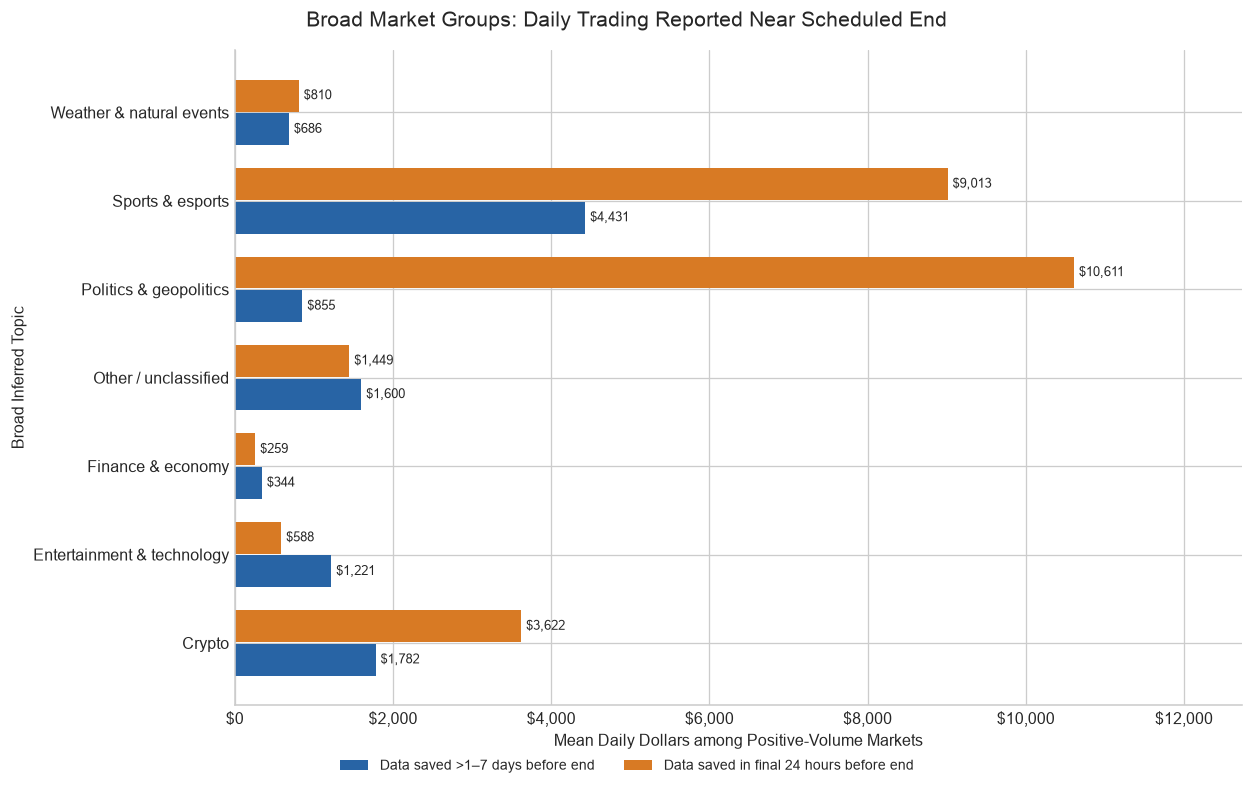

In [34]:
positions = np.arange(len(plot_groups))
fig, ax = plt.subplots(figsize=(11, max(5, 0.7 * len(plot_groups) + 1.8)))
for offset, window, color, legend_label in [
    (-0.19, '1–7 days before end', BLUE, 'Data saved >1–7 days before end'),
    (0.19, 'Final day', ORANGE, 'Data saved in final 24 hours before end'),
]:
    mean_volume = end_comparison.loc[plot_groups, ('mean_when_positive', window)]
    bars = ax.barh(positions + offset, mean_volume, height=0.36, color=color, label=legend_label)
    ax.bar_label(bars, labels=[f'${v:,.0f}' for v in mean_volume], padding=3, fontsize=8)

ax.set_yticks(positions, labels=plot_groups)
ax.set(xlabel='Mean Daily Dollars among Positive-Volume Markets', ylabel='Broad Inferred Topic')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.margins(x=0.2)
fig.suptitle('Broad Market Groups: Daily Trading Reported Near Scheduled End', fontsize=13)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=2,
           frameon=False, bbox_to_anchor=(0.5, -0.025), fontsize=9)
finish(fig, 'additional_01_trading_near_end_by_group')
